C:\Users\Wahaj Raza\AppData\Local\Temp\ipykernel_11568\1086916138.py:27: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  dates = pd.date_range(start=START_DATE, end=END_DATE, freq='3H')


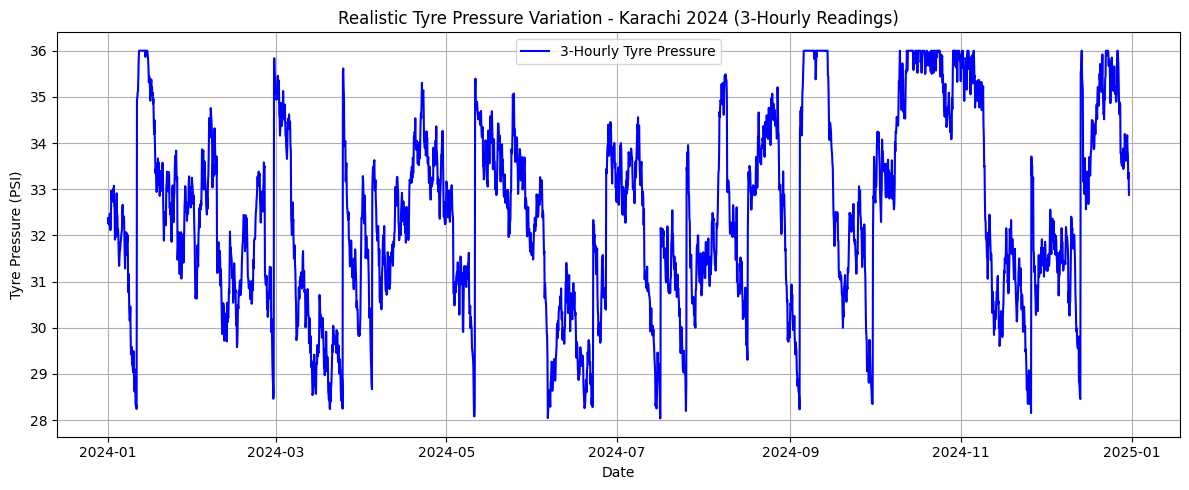

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- Configuration ---
np.random.seed(42)
START_DATE = '2024-01-01'
END_DATE   = '2024-12-31'

# Tyre pressure parameters
BASE_PRESSURE             = 32.0       # Typical nominal pressure in PSI
REFILL_THRESHOLD          = 28.0       # Refill if below this PSI
MAX_PRESSURE              = 36.0       # Upper bound after refill
MIN_PRESSURE              = 26.0       # Floor for realistic data
LEAKAGE_PER_DAY           = 0.10       # ~3 PSI/month (daily leakage)
TEMP_EFFECT_SCALE         = 0.05       # How strongly temperature difference affects PSI
SUDDEN_DROP_PROB          = 0.01       # 1% chance of sudden drop each interval
SUDDEN_DROP_RANGE         = (0.5, 2.0) # Range of sudden drop in PSI
MAX_DAYS_BETWEEN_REFILLS  = 60         # Force refill if no refill for 60 days

# For 3-hourly readings, there are 8 intervals per day
INTERVALS_PER_DAY = 24 // 3  # equals 8
LEAKAGE_PER_INTERVAL = LEAKAGE_PER_DAY / INTERVALS_PER_DAY
MAX_INTERVALS_BETWEEN_REFILLS = MAX_DAYS_BETWEEN_REFILLS * INTERVALS_PER_DAY

# --- Generate date range (3-hourly) ---
dates = pd.date_range(start=START_DATE, end=END_DATE, freq='3H')
n_intervals = len(dates)

# --- Simple Karachi temperature model (applied at each timestamp) ---
def karachi_temp_model(day_of_year):
    """
    Rough sine-wave model for Karachi:
      - Peak around day 172 (late June)
      - Mean ~25°C, amplitude ~8°C
    """
    return 25 + 8 * np.sin(2 * np.pi * (day_of_year - 172) / 365)

# Generate temperature array for each 3-hour timestamp
temperature = []
for current_date in dates:
    day_of_year = current_date.day_of_year
    base_temp = karachi_temp_model(day_of_year)
    # Add random variation for each interval
    temp = base_temp + np.random.normal(0, 1.5)
    temperature.append(temp)
temperature = np.array(temperature)

# --- Simulate tyre pressure for each 3-hour interval ---
pressure = np.zeros(n_intervals)
pressure[0] = BASE_PRESSURE + np.random.normal(0, 0.5)  # Start near 32 PSI
intervals_since_refill = 0

for i in range(1, n_intervals):
    prev_pressure = pressure[i - 1]
    
    # Temperature difference from previous interval
    temp_diff = temperature[i] - temperature[i - 1]
    
    # Leakage for this interval
    interval_loss = LEAKAGE_PER_INTERVAL
    
    # Temperature effect on pressure
    temp_effect = TEMP_EFFECT_SCALE * temp_diff
    
    # Random usage noise
    usage_noise = np.random.normal(0, 0.3)
    
    # Compute current pressure
    current_pressure = prev_pressure - interval_loss + temp_effect + usage_noise
    
    # Occasional sudden drop (e.g., rough roads or puncture)
    if np.random.rand() < SUDDEN_DROP_PROB:
        drop_amount = np.random.uniform(*SUDDEN_DROP_RANGE)
        current_pressure -= drop_amount
    
    # Increment intervals since last refill
    intervals_since_refill += 1
    
    # Check refill conditions
    if current_pressure < REFILL_THRESHOLD or intervals_since_refill >= MAX_INTERVALS_BETWEEN_REFILLS:
        # Refill to a random level between BASE_PRESSURE and MAX_PRESSURE
        current_pressure = np.random.uniform(BASE_PRESSURE, MAX_PRESSURE)
        intervals_since_refill = 0
        
    pressure[i] = current_pressure

# Clip final pressures to a realistic range
pressure = np.clip(pressure, MIN_PRESSURE, MAX_PRESSURE)

# --- Create final DataFrame with only two columns ---
df = pd.DataFrame({
    'Date': dates,
    'Tyre_Pressure_PSI': pressure
})

# --- Plot just the tyre pressure ---
plt.figure(figsize=(12, 5))
plt.plot(df['Date'], df['Tyre_Pressure_PSI'], label='3-Hourly Tyre Pressure', color='blue')
plt.title('Realistic Tyre Pressure Variation - Karachi 2024 (3-Hourly Readings)')
plt.xlabel('Date')
plt.ylabel('Tyre Pressure (PSI)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [2]:
df.head()

,Date,Tyre_Pressure_PSI
0,2024-01-01 00:00:00,32.372503
1,2024-01-01 03:00:00,32.253970
2,2024-01-01 06:00:00,32.281160
3,2024-01-01 09:00:00,32.299442
4,2024-01-01 12:00:00,32.219567


In [3]:
# --- (Optional) Save to CSV ---
df.to_csv('tyre_pressure_2024.csv', index=False)